In [1]:
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, mean_absolute_error, mean_squared_error, r2_score
import joblib

In [2]:
search_paths = glob.glob("/kaggle/input/**/krishijal_master_dataset.csv", recursive=True) + glob.glob("**/krishijal_master_dataset.csv", recursive=True) + ["krishijal_master_dataset.csv"]
dataset_path = search_paths[0]
df = pd.read_csv(dataset_path)

In [3]:
df.head()

,record_id,granularity,state,district,zone,latitude,longitude,date,year,month,...,shc_macro_soil_ph_acidic_share_2024_25,shc_macro_soil_ph_neutral_share_2024_25,shc_macro_soil_ph_alkaline_share_2024_25,shc_macro_electrical_conductivity_saline_share_2024_25,shc_micro_zinc_deficient_share_2024_25,shc_micro_iron_deficient_share_2024_25,shc_micro_boron_deficient_share_2024_25,nitrogen_status,soil_ph_character,soil_health_index
0,KMD_M_0001,monthly,Andhra Pradesh,Guntur,South,16.3067,80.4365,NaN,2023,1,...,0.0017,0.931,0.0673,0.0677,0.3824,0.5166,0.0293,Deficient (Low N),Neutral / Balanced,73.8
1,KMD_M_0002,monthly,Andhra Pradesh,Guntur,South,16.3067,80.4365,NaN,2023,2,...,0.0017,0.931,0.0673,0.0677,0.3824,0.5166,0.0293,Deficient (Low N),Neutral / Balanced,73.8
2,KMD_M_0003,monthly,Andhra Pradesh,Guntur,South,16.3067,80.4365,NaN,2023,3,...,0.0017,0.931,0.0673,0.0677,0.3824,0.5166,0.0293,Deficient (Low N),Neutral / Balanced,73.8
3,KMD_M_0004,monthly,Andhra Pradesh,Guntur,South,16.3067,80.4365,NaN,2023,4,...,0.0017,0.931,0.0673,0.0677,0.3824,0.5166,0.0293,Deficient (Low N),Neutral / Balanced,73.8
4,KMD_M_0005,monthly,Andhra Pradesh,Guntur,South,16.3067,80.4365,NaN,2023,5,...,0.0017,0.931,0.0673,0.0677,0.3824,0.5166,0.0293,Deficient (Low N),Neutral / Balanced,73.8


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6654 entries, 0 to 6653
Data columns (total 72 columns):
 #   Column                                                  Non-Null Count  Dtype  
---  ------                                                  --------------  -----  
 0   record_id                                               6654 non-null   object 
 1   granularity                                             6654 non-null   object 
 2   state                                                   6654 non-null   object 
 3   district                                                6654 non-null   object 
 4   zone                                                    6654 non-null   object 
 5   latitude                                                6654 non-null   float64
 6   longitude                                               6654 non-null   float64
 7   date                                                    4758 non-null   object 
 8   year                                  

In [5]:
df.describe()

,latitude,longitude,year,month,day,day_of_year,crop_code,stage_code,crop_coefficient_kc,soil_ph,...,shc_macro_organic_carbon_medium_share_2024_25,shc_macro_organic_carbon_high_share_2024_25,shc_macro_soil_ph_acidic_share_2024_25,shc_macro_soil_ph_neutral_share_2024_25,shc_macro_soil_ph_alkaline_share_2024_25,shc_macro_electrical_conductivity_saline_share_2024_25,shc_micro_zinc_deficient_share_2024_25,shc_micro_iron_deficient_share_2024_25,shc_micro_boron_deficient_share_2024_25,soil_health_index
count,6654.000000,6654.000000,6654.0,6654.000000,4758.000000,4758.000000,6654.000000,6654.000000,6654.000000,6654.000000,...,6654.000000,6654.000000,6654.000000,6654.000000,6654.000000,6654.000000,6654.000000,6654.000000,6654.000000,6654.000000
mean,22.889262,79.839210,2023.0,7.928164,15.754098,243.000000,4.786745,1.658852,0.998918,7.002119,...,0.320341,0.217808,0.103379,0.863226,0.032897,0.051226,0.312738,0.232702,0.370874,71.623670
std,5.787699,6.112466,0.0,2.505838,8.807882,52.832313,2.084290,1.069338,0.208057,0.874123,...,0.218798,0.265035,0.197628,0.196098,0.073413,0.148955,0.253951,0.286111,0.301244,11.856093
min,9.498100,70.457900,2023.0,1.000000,1.000000,152.000000,0.000000,0.000000,0.450000,4.900000,...,0.000000,0.000200,0.000000,0.009200,0.000000,0.000000,0.000000,0.000000,0.000000,30.400000
25%,19.997500,75.787300,2023.0,6.000000,8.000000,197.000000,3.000000,1.000000,0.850000,6.400000,...,0.190300,0.012000,0.000300,0.852200,0.000300,0.000800,0.096500,0.005900,0.094600,63.600000
50%,23.232400,77.600600,2023.0,8.000000,16.000000,243.000000,6.000000,2.000000,1.050000,7.300000,...,0.244800,0.106100,0.002100,0.956200,0.003200,0.004700,0.251800,0.110000,0.299600,72.600000
75%,26.750900,83.373200,2023.0,10.000000,23.000000,289.000000,6.000000,3.000000,1.150000,7.600000,...,0.442400,0.336200,0.088100,0.990300,0.040800,0.021700,0.486900,0.458000,0.675000,76.900000
max,34.553900,96.170000,2023.0,12.000000,31.000000,334.000000,8.000000,3.000000,1.250000,8.500000,...,0.964100,0.981000,0.990600,1.000000,0.401300,1.000000,0.999800,1.000000,1.000000,98.500000


In [6]:
df.isnull().sum()

record_id                                  0
granularity                                0
state                                      0
district                                   0
zone                                       0
                                          ..
shc_micro_iron_deficient_share_2024_25     0
shc_micro_boron_deficient_share_2024_25    0
nitrogen_status                            0
soil_ph_character                          0
soil_health_index                          0
Length: 72, dtype: int64

In [7]:
df = df.dropna(subset=["temperature", "rainfall", "humidity", "effective_soil_wetness", "crop_type", "growth_stage"])
df = df.drop_duplicates()

In [8]:
selected_features = [
    "temperature", "temp_max", "temp_min", "rainfall", "humidity",
    "effective_soil_wetness", "solar_radiation", "soil_ph", "soil_organic_carbon",
    "ndvi", "et0", "etc", "crop_type", "growth_stage"
]
df_train = df[df["granularity"].isin(["daily", "monthly"])].copy()
X = df_train[selected_features].copy()
y_class = df_train["stress_level_code"].copy()
y_reg = df_train["irrigation_priority_index"].copy()

In [9]:
crop_encoder = LabelEncoder()
X["crop_code"] = crop_encoder.fit_transform(X["crop_type"])

stage_encoder = LabelEncoder()
X["stage_code"] = stage_encoder.fit_transform(X["growth_stage"])

feature_cols = [
    "temperature", "temp_max", "temp_min", "rainfall", "humidity",
    "effective_soil_wetness", "solar_radiation", "soil_ph", "soil_organic_carbon",
    "ndvi", "et0", "etc", "crop_code", "stage_code"
]
X = X[feature_cols]

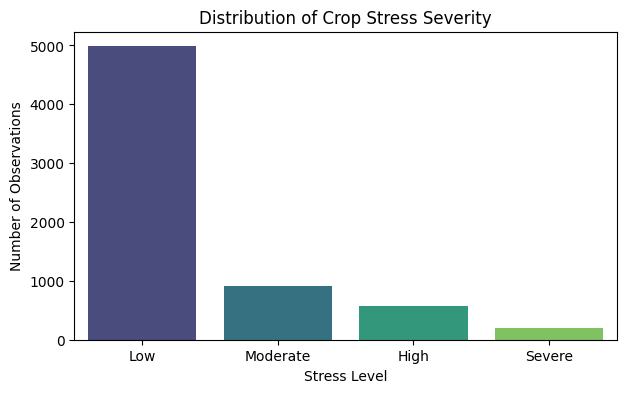

In [10]:
plt.figure(figsize=(7, 4))
sns.countplot(x=df_train["stress_level"], hue=df_train["stress_level"], order=["Low", "Moderate", "High", "Severe"], palette="viridis", legend=False)
plt.title("Distribution of Crop Stress Severity")
plt.xlabel("Stress Level")
plt.ylabel("Number of Observations")
plt.show()

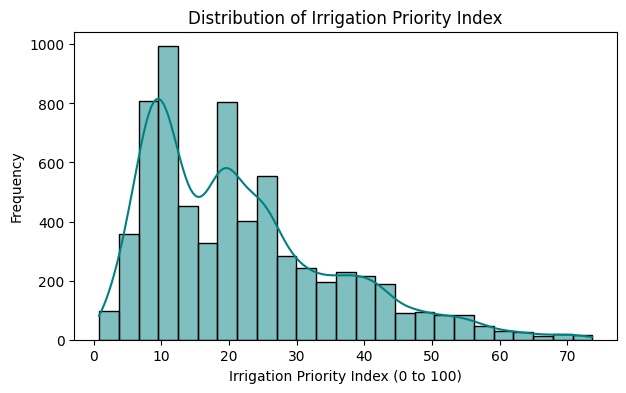

In [11]:
plt.figure(figsize=(7, 4))
sns.histplot(df_train["irrigation_priority_index"], bins=25, kde=True, color="teal")
plt.title("Distribution of Irrigation Priority Index")
plt.xlabel("Irrigation Priority Index (0 to 100)")
plt.ylabel("Frequency")
plt.show()

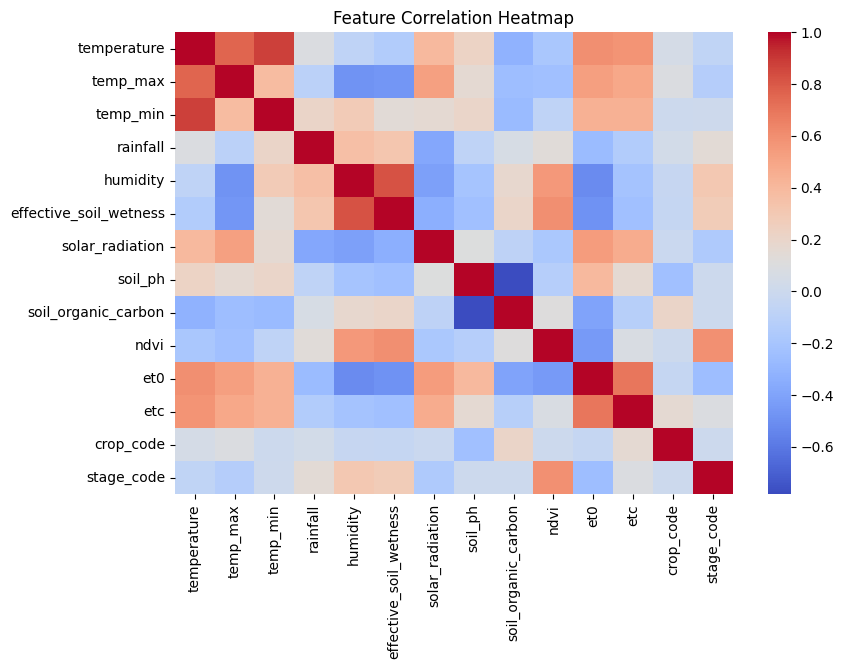

In [12]:
plt.figure(figsize=(9, 6))
sns.heatmap(X.corr(), annot=False, cmap="coolwarm")
plt.title("Feature Correlation Heatmap")
plt.show()

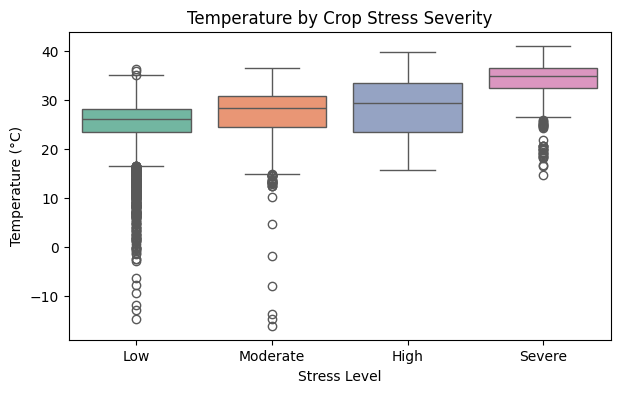

In [13]:
plt.figure(figsize=(7, 4))
sns.boxplot(x=df_train["stress_level"], y=df_train["temperature"], hue=df_train["stress_level"], order=["Low", "Moderate", "High", "Severe"], palette="Set2", legend=False)
plt.title("Temperature by Crop Stress Severity")
plt.xlabel("Stress Level")
plt.ylabel("Temperature (°C)")
plt.show()

In [14]:
X_train, X_test, y_train_class, y_test_class, y_train_reg, y_test_reg = train_test_split(
    X, y_class, y_reg, test_size=0.2, random_state=42, stratify=y_class
)

scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=feature_cols)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=feature_cols)

In [15]:
model_logreg = LogisticRegression(max_iter=1000, random_state=42)
model_logreg.fit(X_train_scaled, y_train_class)

model_dt_class = DecisionTreeClassifier(max_depth=8, random_state=42)
model_dt_class.fit(X_train_scaled, y_train_class)

model_rf_class = RandomForestClassifier(n_estimators=100, max_depth=12, random_state=42)
model_rf_class.fit(X_train_scaled, y_train_class)

RandomForestClassifier(max_depth=12, random_state=42)

In [16]:
pred_logreg = model_logreg.predict(X_test_scaled)
pred_dt_class = model_dt_class.predict(X_test_scaled)
pred_rf_class = model_rf_class.predict(X_test_scaled)

classification_comparison = pd.DataFrame({
    "Algorithm": ["Logistic Regression", "Decision Tree Classifier", "Random Forest Classifier"],
    "Accuracy": [
        accuracy_score(y_test_class, pred_logreg),
        accuracy_score(y_test_class, pred_dt_class),
        accuracy_score(y_test_class, pred_rf_class)
    ],
    "Precision": [
        precision_score(y_test_class, pred_logreg, average="weighted", zero_division=0),
        precision_score(y_test_class, pred_dt_class, average="weighted", zero_division=0),
        precision_score(y_test_class, pred_rf_class, average="weighted", zero_division=0)
    ],
    "Recall": [
        recall_score(y_test_class, pred_logreg, average="weighted", zero_division=0),
        recall_score(y_test_class, pred_dt_class, average="weighted", zero_division=0),
        recall_score(y_test_class, pred_rf_class, average="weighted", zero_division=0)
    ],
    "F1-Score": [
        f1_score(y_test_class, pred_logreg, average="weighted", zero_division=0),
        f1_score(y_test_class, pred_dt_class, average="weighted", zero_division=0),
        f1_score(y_test_class, pred_rf_class, average="weighted", zero_division=0)
    ]
})
classification_comparison

,Algorithm,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.960180,0.960591,0.960180,0.960267
1,Decision Tree Classifier,0.994741,0.994826,0.994741,0.994749
2,Random Forest Classifier,0.995492,0.995595,0.995492,0.995498


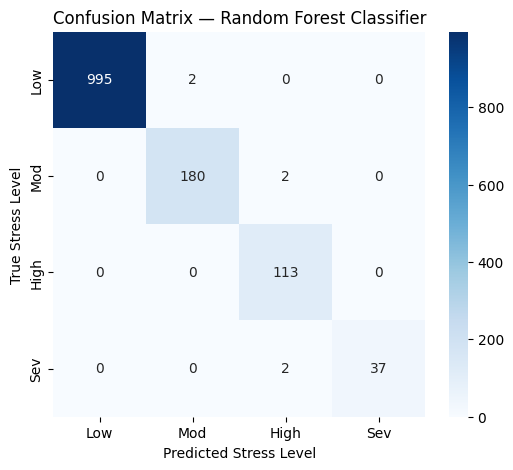

In [17]:
cm = confusion_matrix(y_test_class, pred_rf_class)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Low", "Mod", "High", "Sev"], yticklabels=["Low", "Mod", "High", "Sev"])
plt.title("Confusion Matrix — Random Forest Classifier")
plt.xlabel("Predicted Stress Level")
plt.ylabel("True Stress Level")
plt.show()

In [18]:
model_linreg = LinearRegression()
model_linreg.fit(X_train_scaled, y_train_reg)

model_dt_reg = DecisionTreeRegressor(max_depth=8, random_state=42)
model_dt_reg.fit(X_train_scaled, y_train_reg)

model_rf_reg = RandomForestRegressor(n_estimators=100, max_depth=12, random_state=42)
model_rf_reg.fit(X_train_scaled, y_train_reg)

RandomForestRegressor(max_depth=12, random_state=42)

In [19]:
pred_linreg = model_linreg.predict(X_test_scaled)
pred_dt_reg = model_dt_reg.predict(X_test_scaled)
pred_rf_reg = model_rf_reg.predict(X_test_scaled)

regression_comparison = pd.DataFrame({
    "Algorithm": ["Linear Regression", "Decision Tree Regressor", "Random Forest Regressor"],
    "MAE": [
        mean_absolute_error(y_test_reg, pred_linreg),
        mean_absolute_error(y_test_reg, pred_dt_reg),
        mean_absolute_error(y_test_reg, pred_rf_reg)
    ],
    "MSE": [
        mean_squared_error(y_test_reg, pred_linreg),
        mean_squared_error(y_test_reg, pred_dt_reg),
        mean_squared_error(y_test_reg, pred_rf_reg)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test_reg, pred_linreg)),
        np.sqrt(mean_squared_error(y_test_reg, pred_dt_reg)),
        np.sqrt(mean_squared_error(y_test_reg, pred_rf_reg))
    ],
    "R2 Score": [
        r2_score(y_test_reg, pred_linreg),
        r2_score(y_test_reg, pred_dt_reg),
        r2_score(y_test_reg, pred_rf_reg)
    ]
})
regression_comparison

,Algorithm,MAE,MSE,RMSE,R2 Score
0,Linear Regression,4.866941,37.190888,6.098433,0.805491
1,Decision Tree Regressor,1.197529,4.025733,2.006423,0.978945
2,Random Forest Regressor,0.453817,0.912703,0.955355,0.995227


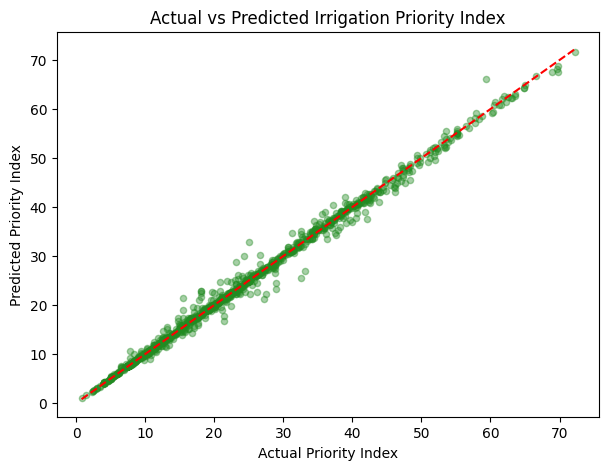

In [20]:
plt.figure(figsize=(7, 5))
plt.scatter(y_test_reg, pred_rf_reg, alpha=0.4, color="forestgreen", s=20)
plt.plot([y_test_reg.min(), y_test_reg.max()], [y_test_reg.min(), y_test_reg.max()], color="red", linestyle="--")
plt.title("Actual vs Predicted Irrigation Priority Index")
plt.xlabel("Actual Priority Index")
plt.ylabel("Predicted Priority Index")
plt.show()

In [21]:
param_grid = {
    "n_estimators": [50, 100],
    "max_depth": [8, 12]
}
grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    cv=3,
    scoring="accuracy",
    n_jobs=-1
)
grid_search.fit(X_train_scaled, y_train_class)
best_model = grid_search.best_estimator_
grid_search.best_params_

{'max_depth': 12, 'n_estimators': 100}

In [22]:
joblib.dump(scaler, "feature_scaler.pkl")
joblib.dump(best_model, "crop_stress_classifier.pkl")
joblib.dump(model_rf_reg, "irrigation_priority_regressor.pkl")
joblib.dump(model_dt_class, "crop_stress_decision_tree.pkl")
joblib.dump(model_logreg, "crop_stress_logistic_regression.pkl")
joblib.dump(model_dt_reg, "irrigation_decision_tree.pkl")
joblib.dump(model_linreg, "irrigation_linear_regression.pkl")

['irrigation_linear_regression.pkl']

In [23]:
df_districts = df[df["granularity"] == "district_baseline"].copy().reset_index(drop=True)
df_districts.head()

,record_id,granularity,state,district,zone,latitude,longitude,date,year,month,...,shc_macro_soil_ph_acidic_share_2024_25,shc_macro_soil_ph_neutral_share_2024_25,shc_macro_soil_ph_alkaline_share_2024_25,shc_macro_electrical_conductivity_saline_share_2024_25,shc_micro_zinc_deficient_share_2024_25,shc_micro_iron_deficient_share_2024_25,shc_micro_boron_deficient_share_2024_25,nitrogen_status,soil_ph_character,soil_health_index


In [24]:
print("Original df:", df.shape)

print("District df:", df_districts.shape)

print("\nOriginal columns:")

print(df.columns.tolist())

print("\nDistrict columns:")

print(df_districts.columns.tolist())

print("\nFirst 5 original records:")

print(df.head())


Original df: (6654, 72)
District df: (0, 72)

Original columns:
['record_id', 'granularity', 'state', 'district', 'zone', 'latitude', 'longitude', 'date', 'year', 'month', 'month_name', 'day', 'day_of_year', 'season', 'crop_type', 'crop_code', 'growth_stage', 'stage_code', 'crop_coefficient_kc', 'soil_type', 'soil_ph', 'soil_organic_carbon', 'field_capacity', 'wilting_point', 'temperature', 'temp_max', 'temp_min', 'rainfall', 'humidity', 'surface_soil_moisture', 'root_zone_soil_moisture', 'solar_radiation', 'et0', 'etc', 'effective_soil_wetness', 'stress_coefficient_ks', 'eta', 'cwsi', 'water_deficit', 'ndvi', 'irrigation_priority_index', 'stress_level', 'stress_level_code', 'irrigation_priority', 'irrigation_priority_code', 'cluster_id', 'pca_x', 'pca_y', 'state_lgd_code', 'district_lgd_code', 'shc_macro_nitrogen_low_share_2024_25', 'shc_macro_nitrogen_medium_share_2024_25', 'shc_macro_nitrogen_high_share_2024_25', 'shc_macro_phosphorus_low_share_2024_25', 'shc_macro_phosphorus_medium

In [25]:
print("Granularity:")
print(df['granularity'].value_counts())

print("\nUnique districts:")
print(df['district'].nunique())

print("\nDistrict names:")
print(df['district'].unique()[:30])

Granularity:
granularity
daily      4758
monthly    1896
Name: count, dtype: int64

Unique districts:
159

District names:
['Guntur' 'Krishna' 'Kurnool' 'Anantapur' 'East Godavari' 'Papum Pare'
 'Changlang' 'West Kameng' 'East Siang' 'Lohit' 'Jorhat' 'Nagaon' 'Kamrup'
 'Cachar' 'Dibrugarh' 'Patna' 'Gaya' 'Muzaffarpur' 'Bhagalpur' 'Nalanda'
 'Raipur' 'Durg' 'Bilaspur' 'Rajnandgaon' 'Bastar' 'North Goa' 'South Goa'
 'Tiswadi' 'Salcete' 'Bardez']


In [26]:
df_districts = df.drop_duplicates(
    subset=['state', 'district']
).copy()

print("Total records:", len(df_districts))
print("Unique districts:", df_districts['district'].nunique())

Total records: 160
Unique districts: 159


In [27]:
if len(df_districts) > 0:

    X_732 = df_districts[feature_cols].copy()

    X_732_scaled = pd.DataFrame(
        scaler.transform(X_732),
        columns=feature_cols,
        index=X_732.index
    )

    print("Scaling completed successfully!")
    
else:
    print("Error: No district records found!")

Scaling completed successfully!


In [28]:
df_districts["Irrigation_Priority_Index"] = np.round(np.clip(model_rf_reg.predict(X_732_scaled), 0.0, 100.0), 1)
df_districts["Stress_Level_Code"] = model_rf_class.predict(X_732_scaled)
stress_label_dict = {0: "Low", 1: "Moderate", 2: "High", 3: "Severe"}
df_districts["Crop_Water_Stress"] = df_districts["Stress_Level_Code"].map(stress_label_dict)

df_districts["Priority_Category"] = np.where(
    df_districts["Irrigation_Priority_Index"] >= 50.0, "High Priority",
    np.where(df_districts["Irrigation_Priority_Index"] >= 35.0, "Medium Priority", "Low Priority")
)

df_districts["Recommended_Water_Depth"] = np.where(
    df_districts["Irrigation_Priority_Index"] >= 50.0, "40–50 mm",
    np.where(df_districts["Irrigation_Priority_Index"] >= 35.0, "25–35 mm", "Routine / Nil")
)

df_ranked_732 = df_districts.sort_values(by="Irrigation_Priority_Index", ascending=False).reset_index(drop=True)
df_ranked_732["Rank"] = range(1, len(df_ranked_732) + 1)
df_ranked_732[["Rank", "district", "state", "Irrigation_Priority_Index", "Priority_Category", "Recommended_Water_Depth"]].head(10)

,Rank,district,state,Irrigation_Priority_Index,Priority_Category,Recommended_Water_Depth
0,1,Bikaner,Rajasthan,64.1,High Priority,40–50 mm
1,2,Pantnagar,Uttarakhand,52.3,High Priority,40–50 mm
2,3,Banaskantha,Gujarat,50.8,High Priority,40–50 mm
3,4,Anand,Gujarat,45.4,Medium Priority,25–35 mm
4,5,Jaipur,Rajasthan,44.1,Medium Priority,25–35 mm
5,6,Hisar,Haryana,43.9,Medium Priority,25–35 mm
6,7,South Goa,Goa,42.9,Medium Priority,25–35 mm
7,8,Tiswadi,Goa,42.9,Medium Priority,25–35 mm
8,9,North Goa,Goa,42.9,Medium Priority,25–35 mm
9,10,Salcete,Goa,42.8,Medium Priority,25–35 mm


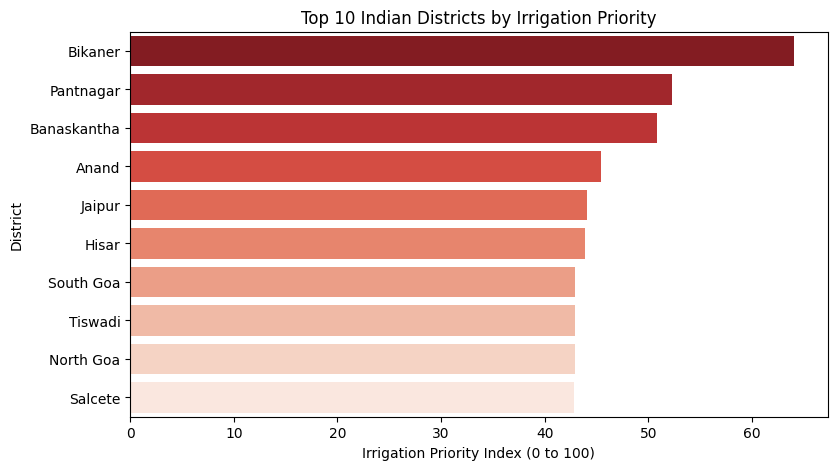

In [29]:
plt.figure(figsize=(9, 5))
top10_districts = df_ranked_732.head(10)
sns.barplot(
    data=top10_districts,
    x="Irrigation_Priority_Index",
    y="district",
    hue="district",
    palette="Reds_r",
    legend=False
)
plt.title("Top 10 Indian Districts by Irrigation Priority")
plt.xlabel("Irrigation Priority Index (0 to 100)")
plt.ylabel("District")
plt.show()

In [30]:
priority_summary = df_ranked_732["Priority_Category"].value_counts()
priority_summary

Priority_Category
Low Priority       131
Medium Priority     26
High Priority        3
Name: count, dtype: int64

In [31]:
clustering_features = [
    "temperature", "rainfall", "humidity", "effective_soil_wetness",
    "solar_radiation", "soil_ph", "soil_organic_carbon", "ndvi", "et0", "etc"
]
scaler_clustering = StandardScaler()
X_cluster_scaled = scaler_clustering.fit_transform(df_ranked_732[clustering_features])

kmeans_model = KMeans(n_clusters=4, random_state=42, n_init=10)
df_ranked_732["Cluster_ID"] = kmeans_model.fit_predict(X_cluster_scaled)

zone_names = {
    0: "Zone 0: Cool Mountain & High-Altitude",
    1: "Zone 1: Humid Coastal & Floodplain",
    2: "Zone 2: Semi-Arid & Deficit Core",
    3: "Zone 3: Wet Tropical & Heavy Rain"
}
df_ranked_732["Cluster_Zone"] = df_ranked_732["Cluster_ID"].map(zone_names)
df_ranked_732["Cluster_Zone"].value_counts()

Cluster_Zone
Zone 1: Humid Coastal & Floodplain       64
Zone 0: Cool Mountain & High-Altitude    55
Zone 2: Semi-Arid & Deficit Core         40
Zone 3: Wet Tropical & Heavy Rain         1
Name: count, dtype: int64

In [32]:
pca_model = PCA(n_components=2, random_state=42)
pca_coordinates = pca_model.fit_transform(X_cluster_scaled)
df_ranked_732["PCA_X"] = np.round(pca_coordinates[:, 0], 2)
df_ranked_732["PCA_Y"] = np.round(pca_coordinates[:, 1], 2)
pca_model.explained_variance_ratio_

array([0.40423408, 0.3040408 ])

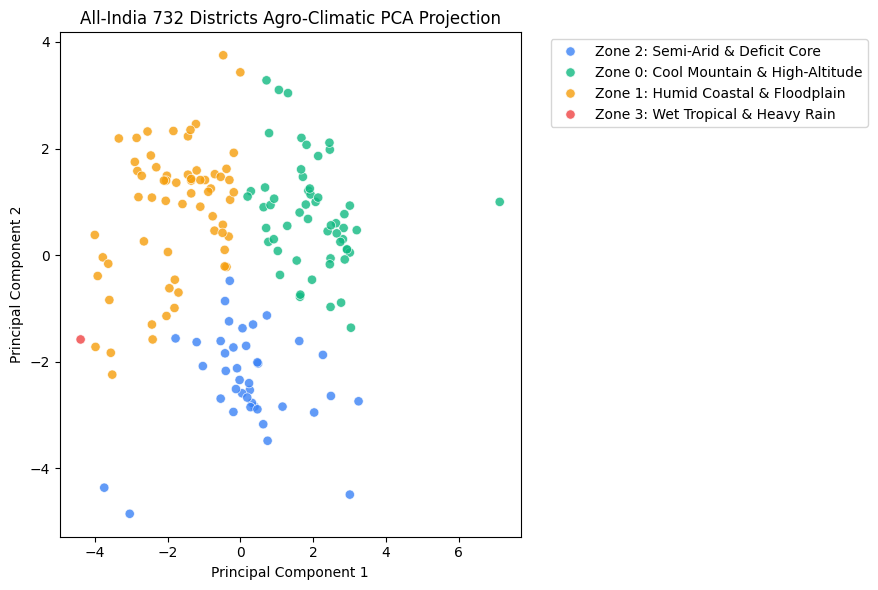

In [33]:
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df_ranked_732,
    x="PCA_X",
    y="PCA_Y",
    hue="Cluster_Zone",
    palette=["#3b82f6", "#10b981", "#f59e0b", "#ef4444"],
    alpha=0.8,
    s=45
)
plt.title("All-India 732 Districts Agro-Climatic PCA Projection")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [34]:
cluster_characterization = df_ranked_732.groupby("Cluster_Zone")[
    ["temperature", "rainfall", "humidity", "effective_soil_wetness", "Irrigation_Priority_Index"]
].mean().round(2)
cluster_characterization

,temperature,rainfall,humidity,effective_soil_wetness,Irrigation_Priority_Index
Cluster_Zone,,,,,
Zone 0: Cool Mountain & High-Altitude,22.43,0.19,54.68,0.48,25.99
Zone 1: Humid Coastal & Floodplain,13.67,0.56,63.56,0.60,15.27
Zone 2: Semi-Arid & Deficit Core,12.87,0.57,46.10,0.38,35.80
Zone 3: Wet Tropical & Heavy Rain,8.94,12.34,88.71,0.84,5.10


In [35]:
df_ranked_732.to_csv("all_india_732_districts_priority_and_clusters.csv", index=False)
df_ranked_732.shape

(160, 82)